# MSBA 502 Project

M.V.Martins, D. Tolledo, J. Machado, L. M.T. Baptista, V.Realinho. (2021) "Early prediction of student’s performance in higher education: a case study" Trends and Applications in Information Systems and Technologies, vol.1, in Advances in Intelligent Systems and Computing series. Springer. DOI: 10.1007/978-3-030-72657-7_16

---
## Import required libraries.
---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

---
## Data Ingestion and Initial Inspection.
---

In [2]:
# Load the dataset into a pandas df
df_uci_raw = pd.read_csv('../data/raw/uci_student_dropout_2021.csv', sep=';')

# Initial inspection
display(df_uci_raw.head(10))
print()
print(df_uci_raw.info())

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate
5,2,39,1,9991,0,19,133.1,1,37,37,...,0,5,17,5,11.500000,5,16.2,0.3,-0.92,Graduate
6,1,1,1,9500,1,1,142.0,1,19,38,...,0,8,8,8,14.345000,0,15.5,2.8,-4.06,Graduate
7,1,18,4,9254,1,1,119.0,1,37,37,...,0,5,5,0,0.000000,0,15.5,2.8,-4.06,Dropout
8,1,1,3,9238,1,1,137.0,62,1,1,...,0,6,7,6,14.142857,0,16.2,0.3,-0.92,Graduate
9,1,1,1,9238,1,1,138.0,1,1,19,...,0,6,14,2,13.500000,0,8.9,1.4,3.51,Dropout



<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          442

---
## Clean and standardize column names.
---

In [3]:
# Create a clean copy to preserve the raw data
df_uci_clean = df_uci_raw.copy()

# Convert all column names to lowercase and replace spaces with underscores (snake_case);
# Also remove all special characters
df_uci_clean.columns = (
    df_uci_clean.columns
    .str.lower()
    .str.replace(' ', '_')
    .str.replace("'", "")
    .str.replace('(', '')       # Remove open parenthesis
    .str.replace(')', '')       # Remove closed parenthesis
    .str.replace('/', '_')      # Replace slash with underscore
    .str.replace('\t', '')      # Remove trailing tab character
)

# Verify the new, clean column names
print(df_uci_clean.columns)

Index(['marital_status', 'application_mode', 'application_order', 'course',
       'daytime_evening_attendance', 'previous_qualification',
       'previous_qualification_grade', 'nacionality', 'mothers_qualification',
       'fathers_qualification', 'mothers_occupation', 'fathers_occupation',
       'admission_grade', 'displaced', 'educational_special_needs', 'debtor',
       'tuition_fees_up_to_date', 'gender', 'scholarship_holder',
       'age_at_enrollment', 'international',
       'curricular_units_1st_sem_credited',
       'curricular_units_1st_sem_enrolled',
       'curricular_units_1st_sem_evaluations',
       'curricular_units_1st_sem_approved', 'curricular_units_1st_sem_grade',
       'curricular_units_1st_sem_without_evaluations',
       'curricular_units_2nd_sem_credited',
       'curricular_units_2nd_sem_enrolled',
       'curricular_units_2nd_sem_evaluations',
       'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade',
       'curricular_units_2nd_sem_wit

---
## Structural data transformations
### (1) Eliminate Data Leakage
* Drop all variables associated with the second semester. An early warning classification model designed to identify at-risk students during their first term must not train on data generated after that term concludes.

### (2) Engineer the Binary Target Variable
* Transform the original multiclass text column (target) into a binary numeric column (target_binary). Map "Dropout" to 1 (the positive class representing the risk event) and group "Enrolled" and "Graduate" into 0 (the retained class).

---

In [4]:
# Drop all 2nd-semester variables
columns_to_drop = [col for col in df_uci_clean.columns if '2nd_sem' in col]
df_uci_clean = df_uci_clean.drop(columns=columns_to_drop)

# Engineer the binary target variable
# 1 = Dropout, 0 = Retained (Enrolled or Graduate)
df_uci_clean['target_binary'] = np.where(df_uci_clean['target'] == 'Dropout', 1, 0)

# Drop the original text target column to prevent redundancy
df_uci_clean = df_uci_clean.drop(columns=['target'])

# Verify the changes
print(df_uci_clean.info())
print()
print(df_uci_clean['target_binary'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 31 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   marital_status                                4424 non-null   int64  
 1   application_mode                              4424 non-null   int64  
 2   application_order                             4424 non-null   int64  
 3   course                                        4424 non-null   int64  
 4   daytime_evening_attendance                    4424 non-null   int64  
 5   previous_qualification                        4424 non-null   int64  
 6   previous_qualification_grade                  4424 non-null   float64
 7   nacionality                                   4424 non-null   int64  
 8   mothers_qualification                         4424 non-null   int64  
 9   fathers_qualification                         4424 non-null   int64  
 10 

---
## Map the numeric categorical codes to their corresponding text labels to establish readable exploratory visualizations.
Revert the encoded variables in the dataset (like `course` or `marital_status`) back from their numeric categorical codes to their text mapping to generate readable visualizations for Exploratory Data Analysis.

---

In [5]:
# Create a copy of the dataframe specifically for EDA visualizations
df_eda = df_uci_clean.copy()

# Define the mapping dictionaries based on the dataset codebook
marital_map = {1: 'Single', 2: 'Married', 3: 'Widowed', 4: 'Divorced', 5: 'Facto Union', 6: 'Legally Separated'}
gender_map = {0: 'Female', 1: 'Male'}
binary_map = {0: 'No', 1: 'Yes'}

course_map = {
    33: 'Biofuel Production', 171: 'Animation & Multimedia', 8014: 'Social Service', 
    9003: 'Agronomy', 9070: 'Communication Design', 9085: 'Veterinary Nursing', 
    9119: 'Informatics Engineering', 9130: 'Equinculture', 9147: 'Management', 
    9238: 'Social Service (Evening)', 9254: 'Tourism', 9500: 'Nursing', 
    9556: 'Oral Hygiene', 9670: 'Advertising & Marketing', 9773: 'Journalism', 
    9853: 'Basic Education', 9991: 'Management (Evening)'
}

# Apply the text mappings
df_eda['marital_status'] = df_eda['marital_status'].map(marital_map)
df_eda['gender'] = df_eda['gender'].map(gender_map)
df_eda['course'] = df_eda['course'].map(course_map)

# Map the binary status variables using a loop
binary_columns = ['displaced', 'educational_special_needs', 'debtor', 
                  'tuition_fees_up_to_date', 'scholarship_holder', 'international']

for col in binary_columns:
    df_eda[col] = df_eda[col].map(binary_map)

# Verify the text mappings
print(df_eda[['marital_status', 'gender', 'course', 'debtor', 'tuition_fees_up_to_date']].sample(10))
print()
display(df_eda.head())

     marital_status  gender                    course debtor  \
2660        Married    Male      Management (Evening)     No   
722          Single    Male    Animation & Multimedia     No   
4096       Divorced  Female            Social Service     No   
493          Single  Female        Veterinary Nursing    Yes   
907          Single  Female  Social Service (Evening)     No   
3452         Single  Female                   Nursing     No   
867          Single    Male   Informatics Engineering     No   
1631        Married    Male                Journalism    Yes   
2778         Single  Female                  Agronomy     No   
2466         Single    Male   Informatics Engineering     No   

     tuition_fees_up_to_date  
2660                     Yes  
722                      Yes  
4096                     Yes  
493                      Yes  
907                      Yes  
3452                     Yes  
867                      Yes  
1631                      No  
2778            

,marital_status,application_mode,application_order,course,daytime_evening_attendance,previous_qualification,previous_qualification_grade,nacionality,mothers_qualification,fathers_qualification,...,curricular_units_1st_sem_credited,curricular_units_1st_sem_enrolled,curricular_units_1st_sem_evaluations,curricular_units_1st_sem_approved,curricular_units_1st_sem_grade,curricular_units_1st_sem_without_evaluations,unemployment_rate,inflation_rate,gdp,target_binary
0,Single,17,5,Animation & Multimedia,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,1
1,Single,15,1,Tourism,1,1,160.0,1,1,3,...,0,6,6,6,14.000000,0,13.9,-0.3,0.79,0
2,Single,1,5,Communication Design,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,1
3,Single,17,2,Journalism,1,1,122.0,1,38,37,...,0,6,8,6,13.428571,0,9.4,-0.8,-3.12,0
4,Married,39,1,Social Service,0,1,100.0,1,37,38,...,0,6,9,5,12.333333,0,13.9,-0.3,0.79,0


---
## Engineer a feature named `first_generation`.
* Strategic Social Impact Alignment: Educational foundations and granting agencies utilize this specific demographic metric to evaluate the efficacy of socioeconomic mobility programming.
* Dimensionality Reduction: The parental qualification variables suffer from extreme cardinality, containing 44 distinct numerical codes representing various educational tiers. By aggregating these two complex columns into a single binary feature, we a classification model a clean, highly predictive signal while avoiding the mathematical distortion caused by massive dummy variable matrices.

To generate this feature, we will identify the specific numeric codes representing a higher education degree (e.g., bachelor's, master's, doctorate) in the UCI dataset dictionary and then use NumPy to flag students where neither parent holds one of those degrees.

---

In [6]:
# Define the specific numerical codes that represent a Higher Education degree 
# (Verify these exact integers against the UCI data dictionary)
higher_ed_codes = [2, 3, 4, 5, 6, 39, 40, 41, 42, 43, 44]

# Create the binary feature: 1 = First Generation, 0 = Not First Generation
df_uci_clean['first_generation'] = np.where(
    (~df_uci_clean['mothers_qualification'].isin(higher_ed_codes)) & 
    (~df_uci_clean['fathers_qualification'].isin(higher_ed_codes)), 
    1, 
    0
)

# Apply the same logic to the EDA dataframe and map the text for visualization
df_eda['first_generation'] = df_uci_clean['first_generation'].map({1: 'Yes', 0: 'No'})

# Verify the distribution of the new variable
print(df_uci_clean['first_generation'].value_counts())

first_generation
1    3616
0     808
Name: count, dtype: int64


---
## Exploratory Data Analysis (EDA).
Identify the primary drivers of first-term student attrition and generate the required visualizations.

---

### Target Variable Distribution and Library Setup
Establish the baseline attrition rate to understand the class balance. A highly imbalanced dataset requires specific handling during the machine learning phase.

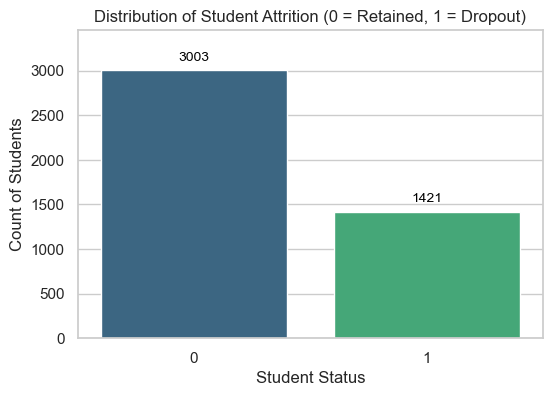

In [7]:
# Set visual style for presentation-ready charts
sns.set_theme(style="whitegrid")

# Visualize the distribution of the binary target variable
# "Dropout" is set to 1 (the positive class representing the risk event) and "Enrolled" and "Graduate" are grouped into 0 (the retained class).
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_eda, x='target_binary', hue='target_binary', palette='viridis', legend=False)
plt.title('Distribution of Student Attrition (0 = Retained, 1 = Dropout)')
plt.xlabel('Student Status')
plt.ylabel('Count of Students')

# Dynamically expand the y-axis to create breathing room for the labels
ax.set_ylim(0, df_eda['target_binary'].value_counts().max() * 1.15)

# Convert the height to an integer before annotating
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')
plt.show()

### Financial and Demographic Intersections
Visualize the intersection of financial security and attrition. This could provide an understanding of how financial distress and scholarship access impact student retention.

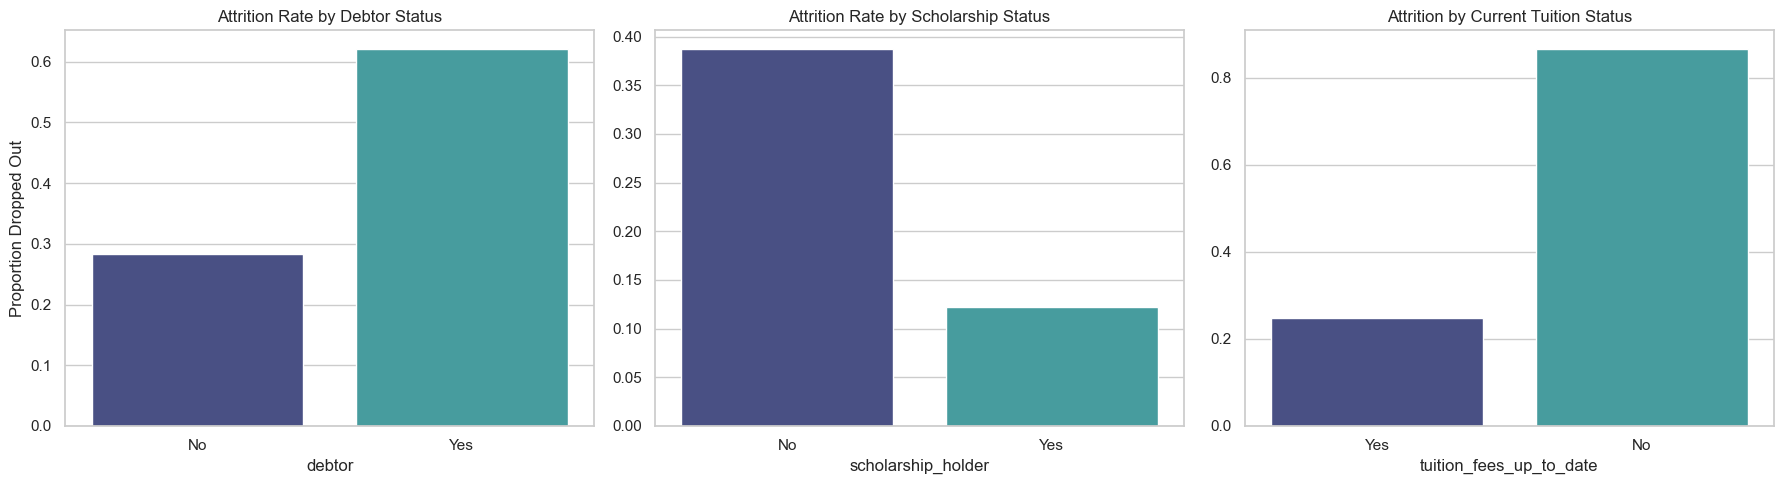

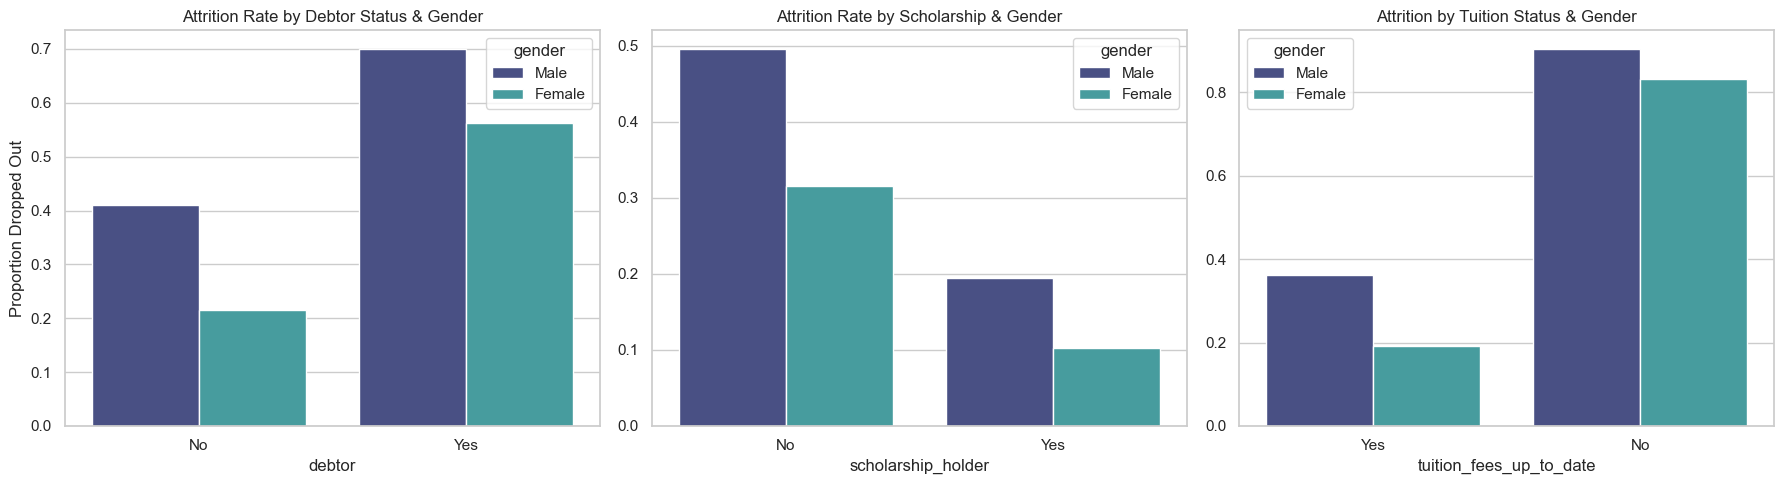

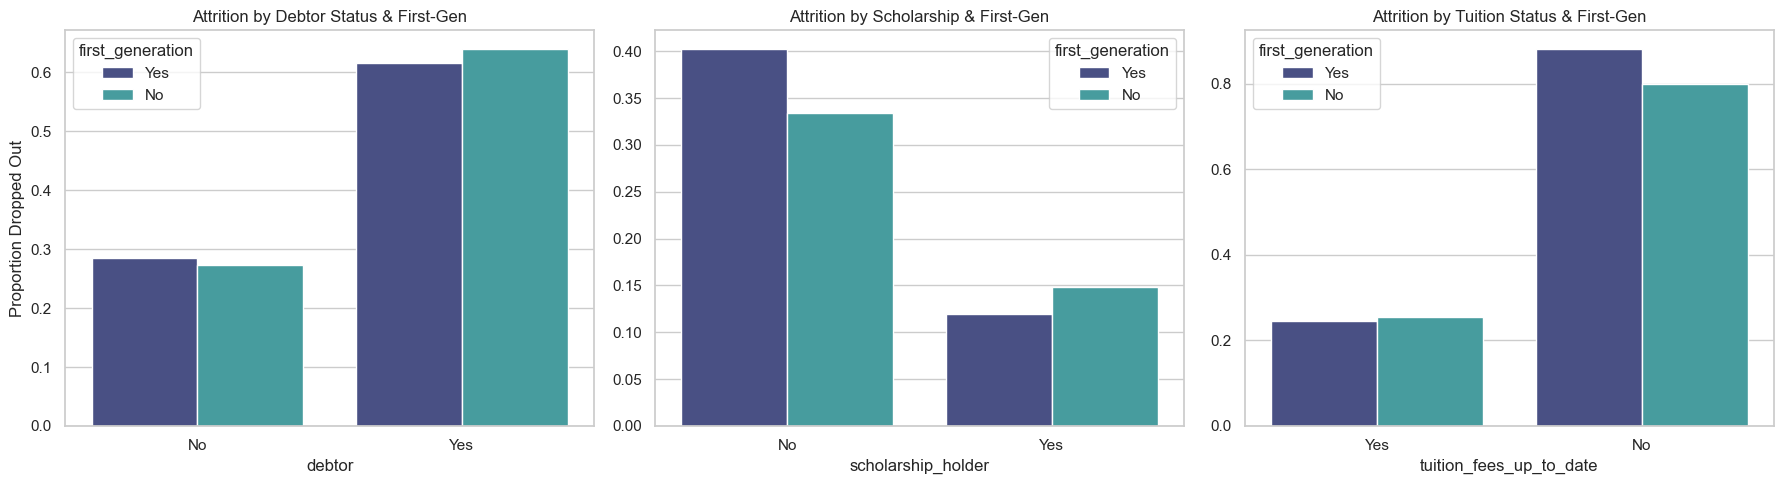

In [8]:
# Baseline Financial Variables
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Map 'x' to 'hue' and set 'legend=False' to resolve the deprecation warning
sns.barplot(data=df_eda, x='debtor', y='target_binary', hue='debtor', legend=False, ax=axes[0], palette='mako', errorbar=None)
axes[0].set_title('Attrition Rate by Debtor Status')
axes[0].set_ylabel('Proportion Dropped Out')

sns.barplot(data=df_eda, x='scholarship_holder', y='target_binary', hue='scholarship_holder', legend=False, ax=axes[1], palette='mako', errorbar=None)
axes[1].set_title('Attrition Rate by Scholarship Status')
axes[1].set_ylabel('')

sns.barplot(data=df_eda, x='tuition_fees_up_to_date', y='target_binary', hue='tuition_fees_up_to_date', legend=False, ax=axes[2], palette='mako', errorbar=None)
axes[2].set_title('Attrition by Current Tuition Status')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()


# Financial Variables Intersected with Gender
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=df_eda, x='debtor', y='target_binary', hue='gender', ax=axes[0], palette='mako', errorbar=None)
axes[0].set_title('Attrition Rate by Debtor Status & Gender')
axes[0].set_ylabel('Proportion Dropped Out')

sns.barplot(data=df_eda, x='scholarship_holder', y='target_binary', hue='gender', ax=axes[1], palette='mako', errorbar=None)
axes[1].set_title('Attrition Rate by Scholarship & Gender')
axes[1].set_ylabel('')

sns.barplot(data=df_eda, x='tuition_fees_up_to_date', y='target_binary', hue='gender', ax=axes[2], palette='mako', errorbar=None)
axes[2].set_title('Attrition by Tuition Status & Gender')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()


# Financial Variables Intersected with First-Generation Status
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=df_eda, x='debtor', y='target_binary', hue='first_generation', ax=axes[0], palette='mako', errorbar=None)
axes[0].set_title('Attrition by Debtor Status & First-Gen')
axes[0].set_ylabel('Proportion Dropped Out')

sns.barplot(data=df_eda, x='scholarship_holder', y='target_binary', hue='first_generation', ax=axes[1], palette='mako', errorbar=None)
axes[1].set_title('Attrition by Scholarship & First-Gen')
axes[1].set_ylabel('')

sns.barplot(data=df_eda, x='tuition_fees_up_to_date', y='target_binary', hue='first_generation', ax=axes[2], palette='mako', errorbar=None)
axes[2].set_title('Attrition by Tuition Status & First-Gen')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()

The visual output above reveals that financial distress operates as an absolute barrier to retention, overriding parental educational background, while gender acts as a systemic risk multiplier.

### Visual Interpretation

* **The Gender Multiplier:** Male students drop out at substantially higher rates than female students across every financial category. A male student without a scholarship drops out at a rate near 50%, whereas a female student in the exact same financial position drops out at approximately 30%.
* **The Financial Equalizer:** The near-identical bar heights in the third row for `debtor` and `tuition_fees_up_to_date` prove that acute financial distress forces attrition equally. If a student cannot pay tuition or carries institutional debt, they drop out regardless of whether they are a first-generation student or a legacy enrollee.
* **The Scholarship Reversal:** First-generation students without scholarships drop out at higher rates (~40%) than non-first-generation students without scholarships (~33%). However, when awarded a scholarship, first-generation students drop out at a *lower* rate than their non-first-generation peers.

### Implications for Modeling
* **Feature Weights:** The machine learning classifier will assign massive predictive weight to `gender`, `tuition_fees_up_to_date`, and `debtor`. The `first_generation` variable will carry a low independent coefficient because its baseline splits mirror the overall population averages.
* **Interaction Terms:** To extract predictive value from the first-generation feature, we must build an interaction term with scholarship status (`first_generation * scholarship_holder`; shown in the middle plot in the 3rd row) during the feature engineering phase. This mathematical combination feeds the classifier the distinct signal that scholarships reverse the first-generation attrition trajectory.

### Initial Presentation Strategy and Possible MSBA 507 Transition
* **The Business Recommendation:** Direct the Director of Student Success to overhaul the algorithmic distribution of emergency financial advising. The data proves male students hold the highest baseline vulnerability to financial hurdles and require proactive intervention.
* **The Social Impact Pitch:** The scholarship reversal finding serves as the explicit bridge to our MSBA 507 coursework. We could use this set of plots to help convince granting agencies that financial aid deployed to first-generation populations does not just equalize outcomes—it actively produces higher retention rates than funding given to students from highly educated families.

---

---
### Academic Performance Disparities
Boxplots reveal the precise distributions of admission grades and first-semester performance, isolating the differences between dropouts and retained students. The boxplots visually establish a disparity, but the t-test mathematically validates whether the difference in academic performance between retained students and dropouts is statistically significant.

---

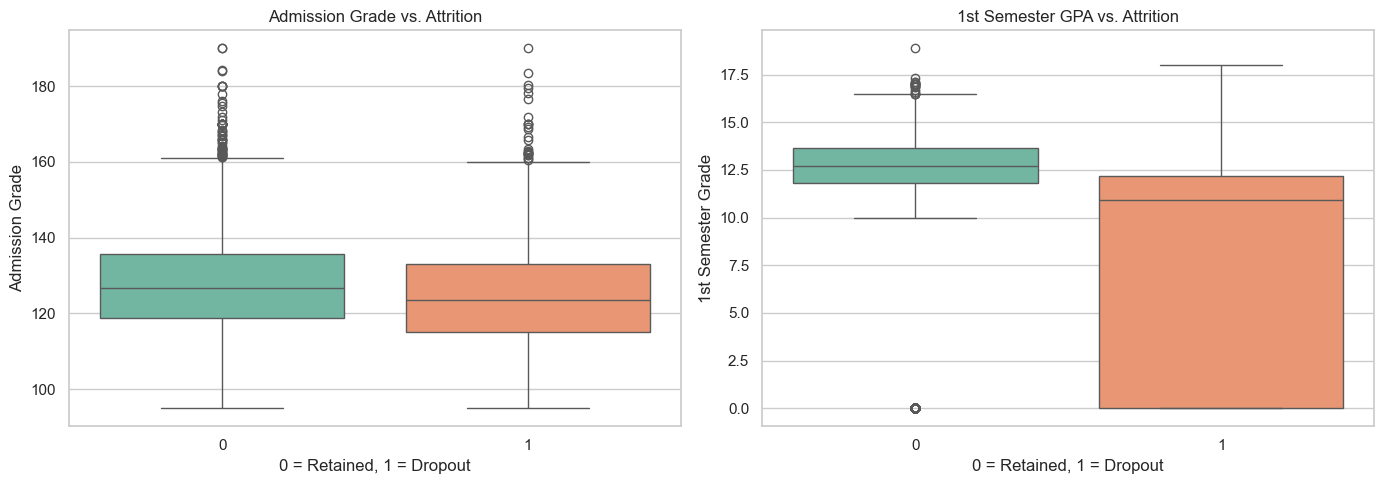


--- Welch's Two-sample t-test for `admission_grade` ---
T-statistic: 6.24
P-value: 5.1815e-10
Conclusion: We reject the null hypothesis. There is a statistically significant difference in admission grades.

--- Welch's Two-sample t-test for `curricular_units_1st_sem_grade` ---
T-statistic: 29.42
P-value: 2.7684e-155
Conclusion: We reject the null hypothesis. There is a statistically significant difference in 1st semester grades.


In [9]:
# Analyze quantitative academic metrics grouped by attrition status
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Admission Grade (Deprecation fixed with hue and legend=False)
sns.boxplot(data=df_eda, x='target_binary', y='admission_grade', hue='target_binary', legend=False, ax=axes[0], palette='Set2')
axes[0].set_title('Admission Grade vs. Attrition')
axes[0].set_xlabel('0 = Retained, 1 = Dropout')
axes[0].set_ylabel('Admission Grade')

# 1st Semester Grade (Deprecation fixed with hue and legend=False)
sns.boxplot(data=df_eda, x='target_binary', y='curricular_units_1st_sem_grade', hue='target_binary', legend=False, ax=axes[1], palette='Set2')
axes[1].set_title('1st Semester GPA vs. Attrition')
axes[1].set_xlabel('0 = Retained, 1 = Dropout')
axes[1].set_ylabel('1st Semester Grade')

plt.tight_layout()
plt.show()
print()

# --- Two-sample t-tests (Welch's) ---

# Isolate the admission grades for each group
grades_retained1 = df_uci_clean[df_uci_clean['target_binary'] == 0]['admission_grade']
grades_dropout1 = df_uci_clean[df_uci_clean['target_binary'] == 1]['admission_grade']

# Execute Welch's two-sample independent t-test (equal_var=False)
t_stat1, p_val1 = ttest_ind(grades_retained1, grades_dropout1, equal_var=False, nan_policy='omit')

print('--- Welch\'s Two-sample t-test for `admission_grade` ---')
print(f"T-statistic: {t_stat1:.2f}")
print(f"P-value: {p_val1:.4e}")
if p_val1 < 0.05:
    print("Conclusion: We reject the null hypothesis. There is a statistically significant difference in admission grades.")
else:
    print("Conclusion: We fail to reject the null hypothesis. The difference is not statistically significant.")
print()

# Isolate the 1st semester grades for each group
grades_retained2 = df_uci_clean[df_uci_clean['target_binary'] == 0]['curricular_units_1st_sem_grade']
grades_dropout2 = df_uci_clean[df_uci_clean['target_binary'] == 1]['curricular_units_1st_sem_grade']

# Execute Welch's two-sample independent t-test (equal_var=False)
t_stat2, p_val2 = ttest_ind(grades_retained2, grades_dropout2, equal_var=False, nan_policy='omit')

print('--- Welch\'s Two-sample t-test for `curricular_units_1st_sem_grade` ---')
print(f"T-statistic: {t_stat2:.2f}")
print(f"P-value: {p_val2:.4e}")
if p_val2 < 0.05:
    print("Conclusion: We reject the null hypothesis. There is a statistically significant difference in 1st semester grades.")
else:
    print("Conclusion: We fail to reject the null hypothesis. The difference is not statistically significant.")

### Linear Correlation Analysis (Preliminary Feature Screening)
This following heatmap mathematically validates our exploratory visualizations by quantifying the linear relationship between each numerical independent variable and the target variable (1 = Dropout). 

It establishes a clear hierarchy of predictive signals: financial stability and first-term academic momentum act as massive retention anchors, while existing debt and older enrollment ages act as risk multipliers. It also justifies dropping macroeconomic variables (GDP, inflation) due to their near-zero linear association with first-term attrition. This analysis is executed strictly on the numerical `df_uci_clean` DataFrame to ensure mathematical validity.

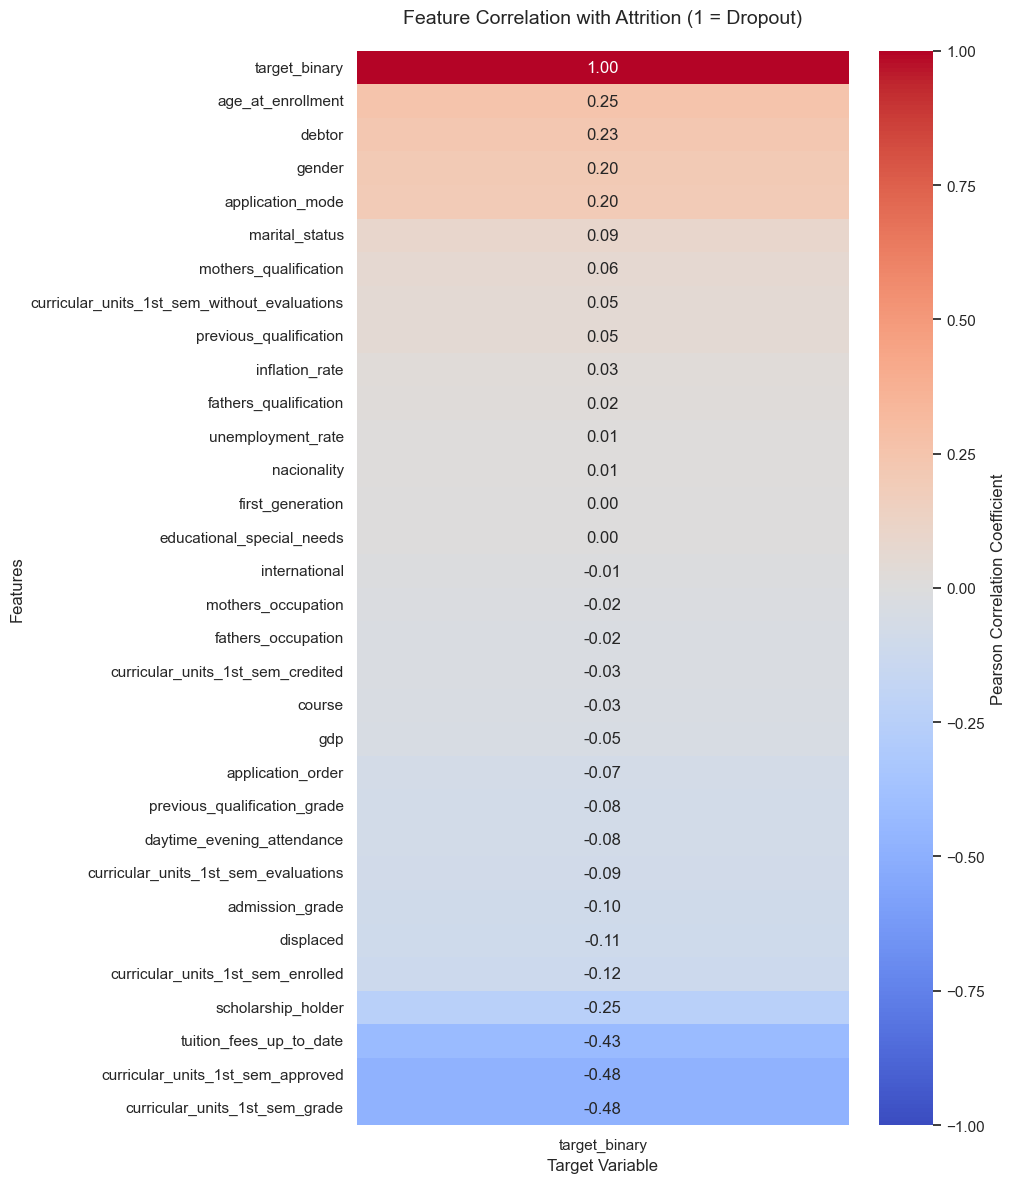

In [10]:
# Generate a correlation heatmap for numerical variables
plt.figure(figsize=(10, 12))

# Select only numeric columns to prevent calculation errors
numeric_cols = df_uci_clean.select_dtypes(include=['int64', 'float64', 'int32']).columns
corr_matrix = df_uci_clean[numeric_cols].corr()

# Isolate the relationships with the target variable and sort
target_corr = corr_matrix[['target_binary']].sort_values(by='target_binary', ascending=False)

# Build the heatmap with a diverging colormap focused on the target
sns.heatmap(target_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f", cbar_kws={'label': 'Pearson Correlation Coefficient'})
plt.title('Feature Correlation with Attrition (1 = Dropout)', pad=20, fontsize=14)
plt.ylabel('Features')
plt.xlabel('Target Variable')

plt.tight_layout()
plt.show()

In [11]:
# Isolate independent numeric predictors (drop the target)
X = df_uci_clean.select_dtypes(include=['int64', 'float64']).drop(columns=['target_binary'])
X = sm.add_constant(X)

# Calculate VIF for each predictor
vif_data = pd.DataFrame()
vif_data["Feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

# Display features with high multicollinearity (VIF > 5)
print(vif_data[vif_data["VIF"] > 5].sort_values(by="VIF", ascending=False))

                              Feature       VIF
25  curricular_units_1st_sem_approved  7.519688
23  curricular_units_1st_sem_enrolled  7.461950
11                 mothers_occupation  5.975732
12                 fathers_occupation  5.958907


---
### Data Pre-Processing & Feature Selection

* **Eliminate Multicollinearity:** Drop `curricular_units_1st_sem_enrolled` due to extreme mathematical overlap with `curricular_units_1st_sem_approved` (VIF > 7). Retaining "approved" units isolates true academic success over mere class registration.
* **Remove High-Cardinality Variables:** Drop `mothers_occupation` and `fathers_occupation`. These nominal columns contain 195 distinct numerical codes that mathematically distort linear calculations and create excessively sparse matrices.
* **Remove Zero-Correlation Variables:** Drop `gdp`, `inflation_rate`, and `unemployment_rate`. Preliminary correlation screening proved these macroeconomic factors hold near-zero predictive correlation with first-term student attrition.
---

In [12]:
# Define features to drop based on VIF and correlation analysis
columns_to_drop_final = [
    'curricular_units_1st_sem_enrolled',
    'mothers_occupation',
    'fathers_occupation',
    'gdp',
    'inflation_rate',
    'unemployment_rate'
]

# Create the final modeling dataframe by dropping the selected columns
df_model = df_uci_clean.drop(columns=columns_to_drop_final)

# Verify the final dataframe structure
print("Final Modeling DataFrame Shape:", df_model.shape)
print("\nFinal Feature List:")
print(df_model.info())

Final Modeling DataFrame Shape: (4424, 26)

Final Feature List:
<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 26 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   marital_status                                4424 non-null   int64  
 1   application_mode                              4424 non-null   int64  
 2   application_order                             4424 non-null   int64  
 3   course                                        4424 non-null   int64  
 4   daytime_evening_attendance                    4424 non-null   int64  
 5   previous_qualification                        4424 non-null   int64  
 6   previous_qualification_grade                  4424 non-null   float64
 7   nacionality                                   4424 non-null   int64  
 8   mothers_qualification                         4424 non-null   int64  
 9   fathers_qu

---
### Machine Learning Classification Pipeline
1. **Define Features ($X$) and Target ($y$):** Separate the binary target variable (`target_binary`) from the predictive features.
2. **Train-Test Split:** Split the data into training and testing sets (80/20 split) to ensure the model can be evaluated on unseen data.
3. **Scale Features (Optional but recommended for Logistic Regression):** Standardize numerical features so variables with larger scales (like age or admission grade) don't disproportionately skew the coefficients.
4. **Train the Logistic Regression Model:** Fit the model using `scikit-learn`.
5. **Evaluate the Model:** Generate a confusion matrix and a classification report to review precision, recall, and overall accuracy.
---

In [15]:
# Define X (independent features) and y (target)
X = df_model.drop(columns=['target_binary'])
y = df_model['target_binary']

# Perform Train-Test Split (80% training, 20% testing, using random_state for reproducibility)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Scale the numerical/continuous features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize and train the Logistic Regression classifier
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

# Predict on the test set and evaluate
y_pred = log_reg.predict(X_test_scaled)

print("--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred))
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred))

--- Confusion Matrix ---
[[567  34]
 [ 98 186]]

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.85      0.94      0.90       601
           1       0.85      0.65      0.74       284

    accuracy                           0.85       885
   macro avg       0.85      0.80      0.82       885
weighted avg       0.85      0.85      0.85       885



---
### Performance Breakdown
* **Overall Accuracy (85%):** The model correctly classifies 85% of the students overall.
* **Class 0 (Retained):** High precision (0.85) and high recall (0.94), yielding a 0.90 F1-score. This means the model is exceptionally good at identifying students who will stay enrolled or graduate.
* **Class 1 (Dropout):** Strong precision (0.85), meaning that when the model flags a student as at-risk of dropping out, it is correct 85% of the time. However, the recall is lower (0.65), meaning the model misses about 35% of actual dropouts.

### Why This Matters for the Stakeholder (Director of Student Success)
For an early warning system, missing at-risk students (false negatives) carries a real cost because those students slip through without receiving advising interventions. However, high precision means limited counseling resources won't be wasted on students who aren't actually at risk.

---

In [16]:
# Extract feature coefficients from the trained logistic regression model
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': log_reg.coef_[0]
})

# Sort by coefficient value (positive = increases dropout risk, negative = decreases dropout risk)
feature_importance = feature_importance.sort_values(by='Coefficient', ascending=False)

print("--- Top Risk Multipliers (Increase Dropout Probability) ---")
print(feature_importance.head(5))
print("\n--- Top Retention Anchors (Decrease Dropout Probability) ---")
print(feature_importance.tail(5))

--- Top Risk Multipliers (Increase Dropout Probability) ---
                              Feature  Coefficient
19  curricular_units_1st_sem_credited     0.953196
3                              course     0.557384
17                  age_at_enrollment     0.402113
7                         nacionality     0.262268
13                             debtor     0.203400

--- Top Retention Anchors (Decrease Dropout Probability) ---
                              Feature  Coefficient
22     curricular_units_1st_sem_grade    -0.258048
16                 scholarship_holder    -0.281032
18                      international    -0.321160
14            tuition_fees_up_to_date    -0.750189
21  curricular_units_1st_sem_approved    -1.860356


### Answering the "So What?": Translating Coefficients into Business Action
The coefficients extracted from the logistic regression model provide the exact empirical evidence required to answer the "so what?" for university stakeholders, such as the Director of Student Success. Because we standardized the features using `StandardScaler`, a one-standard-deviation increase in a given variable shifts the log-odds of a student dropping out by that exact coefficient value.

### Breakdown of what these coefficients mean and how to act on them:

#### 1. The Power of First-Term Momentum (Retention Anchors)
* **`curricular_units_1st_sem_approved` (-1.860) & `curricular_units_1st_sem_grade` (-0.258):** Successfully passing courses and maintaining a high GPA in the first term are the most powerful forces preventing attrition.
    * **The "So What?":** Academic success early on completely dominates all other factors. This proves that academic tracking *during* the first term is vital. If a student falls behind on passed units immediately, they are on a direct trajectory toward dropping out.


* **`tuition_fees_up_to_date` (-0.750):** Being current on tuition payments is a massive protective factor against dropping out.
    * **The "So What?":** Financial stability directly translates to academic persistence. Administrative holds or unpaid balances create an immediate barrier to staying enrolled.

#### 2. The Early Warning Risk Indicators (Risk Multipliers)

* **`curricular_units_1st_sem_credited` (+0.953) & `course` (+0.557):** Students with high numbers of credited units (often transfer students or those entering with advanced standing) and students enrolled in specific high-rigor or misaligned majors face higher dropout probabilities.
    * **The "So What?":** Transfer or non-traditional entry paths do not guarantee smooth sailing; in fact, the transition friction can increase risk. Academic advisors must pay closer attention to students entering with complex credit transfers or into historically volatile programs.


* **`age_at_enrollment` (+0.402) & `debtor` (+0.203):** Older students and students carrying existing financial debt at enrollment have significantly higher risk profiles.
    * **The "So What?":** Non-traditional students face external pressures (work, family) that traditional 18-year-olds do not. Coupled with institutional debt, these students are highly vulnerable.



#### 3. Strategic Recommendations for the Final Presentation
My recommendations are freamed around these findings:

1. **Automated Early Warning Triggers:** The university should build an automated alert system triggered not just by low grades, but specifically when a student fails to pass their initial registered units or falls behind on tuition (`tuition_fees_up_to_date`).
2. **Targeted Financial Advising Interventions:** Because debt is a key risk multiplier (`debtor`), financial counseling should be proactively bundled with academic advising before a student reaches the brink of withdrawing.

---